# Correction – Activité pratique : Bases de PyTorch
Exercices 1 (régression salaires), 2 (MNIST MLP), 3 (Iris), 4 (MNIST CNN).

In [4]:
%pip install matplotlib scikit-learn torchvision

Note: you may need to restart the kernel to use updated packages.


c:\Users\hp\Downloads\ia.generative\.venv\Scripts\python.exe: No module named pip


In [3]:
import sys
print(sys.executable)
!{sys.executable} -m pip install matplotlib scikit-learn torchvision

c:\Users\hp\Downloads\ia.generative\.venv\Scripts\python.exe


c:\Users\hp\Downloads\ia.generative\.venv\Scripts\python.exe: No module named pip


In [4]:
import sys, subprocess
for cmd in (["-m", "ensurepip", "--upgrade"],
            ["-m", "pip", "install", "matplotlib", "scikit-learn", "torchvision"]):
    r = subprocess.run([sys.executable, *cmd], capture_output=True, text=True)
    print(r.stdout[-800:], r.stderr[-800:])

Looking in links: c:\Users\hp\AppData\Local\Temp\tmp4rryshqn
Processing c:\users\hp\appdata\local\temp\tmp4rryshqn\pip-24.0-py3-none-any.whl
 
MB/s eta 0:00:01
   ---------------------------------------  36.6/36.6 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------  36.6/36.6 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 36.6/36.6 MB 4.6 MB/s eta 0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
 
[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



In [2]:
import sys
print(sys.executable)

c:\Users\hp\Downloads\ia.generative\.venv\Scripts\python.exe


In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

---
# Exercice 1 – Régression : salaire = f(ancienneté, expertise)
## 1. Données et exploration

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
torch.manual_seed(42)
n = 300
anciennete = torch.randint(0, 21, (n, 1)).float()
expertise = torch.randint(1, 6, (n, 1)).float()
bruit = torch.randn(n, 1) * 500
salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit
X = torch.cat([anciennete, expertise], dim=1)
y = salaires
print("X :", X.shape, "| y :", y.shape)   # (300, 2) et (300, 1)
print(f"Salaire moyen : {y.mean().item():.2f} DH")

X : torch.Size([300, 2]) | y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


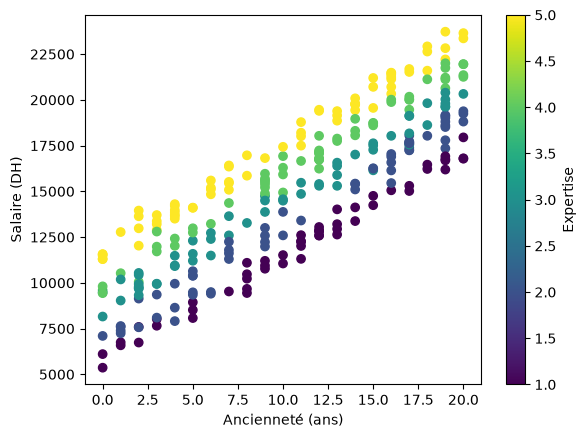

In [4]:
sc = plt.scatter(X[:, 0], y[:, 0], c=X[:, 1], cmap="viridis")
plt.colorbar(sc, label="Expertise")
plt.xlabel("Ancienneté (ans)"); plt.ylabel("Salaire (DH)")
plt.show()

## 2. Séparation train/test et normalisation
Les statistiques (moyenne, écart-type) sont calculées **sur le train uniquement** pour éviter toute fuite de données. Les salaires sont exprimés en milliers de DH pour stabiliser l'entraînement.

In [5]:
indices = torch.randperm(n)
limite = int(0.8 * n)
tr, te = indices[:limite], indices[limite:]
X_train, X_test = X[tr], X[te]
y_train, y_test = y[tr] / 1000, y[te] / 1000

moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)
X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

## 3. Modèle et entraînement

In [6]:
model = nn.Linear(2, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

historique = []
model.train()
for epoch in range(500):
    optimizer.zero_grad()
    predictions = model(X_train_norm)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()
    historique.append(loss.item())
    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


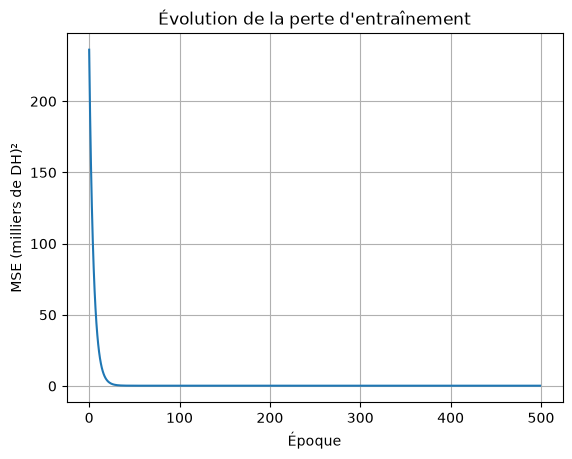

In [7]:
plt.plot(historique); plt.grid()
plt.xlabel("Époque"); plt.ylabel("MSE (milliers de DH)²")
plt.title("Évolution de la perte d'entraînement")
plt.show()

## 4. Évaluation

In [8]:
model.eval()
with torch.no_grad():
    pred_test = model(X_test_norm)
    mae = (pred_test * 1000 - y_test * 1000).abs().mean()
print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


## 5. Nouveau salarié (7 ans, expertise 4/5)

In [9]:
nouveau = torch.tensor([[7.0, 4.0]])
nouveau_norm = (nouveau - moyenne) / ecart_type      # même normalisation que le train
with torch.no_grad():
    salaire_predit = model(nouveau_norm) * 1000
print(f"Salaire estimé : {salaire_predit.item():.2f} DH (théorique ≈ 14200 DH)")

Salaire estimé : 14201.94 DH (théorique ≈ 14200 DH)


## Coefficients en unités d'origine

In [10]:
w = model.weight.detach()[0]
b = model.bias.detach()[0]
coef = w / ecart_type[0] * 1000
intercept = (b - (w * moyenne[0] / ecart_type[0]).sum()) * 1000
print(f"ancienneté={coef[0]:.0f}, expertise={coef[1]:.0f}, constante={intercept:.0f}  (attendu : 600, 1500, 4000)")

ancienneté=593, expertise=1491, constante=4090  (attendu : 600, 1500, 4000)


## Réponses aux questions
- **Interprétation :** à expertise constante, +1 an d'ancienneté ≈ **+600 DH** (coefficient en unités d'origine).
- **La perte n'est jamais nulle :** le bruit (σ = 500 DH) n'est pas explicable par les deux variables ; la MSE minimale atteignable ≈ σ² = 0,25 (en milliers de DH)².
- **40 ans d'ancienneté :** extrapolation hors du domaine d'entraînement (0–20 ans) → rien ne garantit que la relation reste linéaire, prédiction peu fiable.
- **Plus de bruit :** MAE plus grande, perte minimale plus élevée, coefficients moins précis.

---
# Fonctions communes MNIST (Exercices 2 et 4)

In [11]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def charger_mnist(normaliser):
    tfs = [transforms.ToTensor()]
    if normaliser:
        tfs.append(transforms.Normalize((0.1307,), (0.3081,)))
    transform = transforms.Compose(tfs)
    train = datasets.MNIST("./data", train=True, download=True, transform=transform)
    test = datasets.MNIST("./data", train=False, download=True, transform=transform)
    return (train, test,
            DataLoader(train, batch_size=64, shuffle=True),
            DataLoader(test, batch_size=256, shuffle=False))

def entrainer(model, train_loader, n_train, epochs):
    criterion = nn.CrossEntropyLoss()          # attend des logits + labels entiers (pas de Softmax)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
        print(f"Époque {epoch + 1}/{epochs} | Perte : {total / n_train:.4f}")

def predire_tout(model, loader):
    model.eval()
    preds, vrais, imgs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            preds.append(model(images.to(device)).argmax(dim=1).cpu())
            vrais.append(labels); imgs.append(images)
    return torch.cat(preds), torch.cat(vrais), torch.cat(imgs)

def afficher_erreurs(imgs, vrais, preds, normalise):
    idx = (preds != vrais).nonzero().flatten()[:10]
    fig, axes = plt.subplots(2, 5, figsize=(10, 5))
    for ax, i in zip(axes.flatten(), idx):
        img = imgs[i, 0]
        if normalise:
            img = img * 0.3081 + 0.1307
        ax.imshow(img.numpy(), cmap="gray")
        ax.set_title(f"vrai={vrais[i].item()} / prédit={preds[i].item()}")
        ax.axis("off")
    plt.tight_layout(); plt.show()

---
# Exercice 2 – MNIST avec un MLP
## Données et modèle

In [12]:
torch.manual_seed(42)
train, test, train_loader, test_loader = charger_mnist(normaliser=False)

def creer_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 128), nn.ReLU(),
                         nn.Linear(128, 10)).to(device)

model = creer_mlp()
entrainer(model, train_loader, len(train), epochs=5)

100.0%
100.0%
100.0%
100.0%


Époque 1/5 | Perte : 0.3448
Époque 2/5 | Perte : 0.1580
Époque 3/5 | Perte : 0.1083
Époque 4/5 | Perte : 0.0812
Époque 5/5 | Perte : 0.0640


## Évaluation : Accuracy, Précision, Rappel, F1
Multiclasse → moyenne `macro` (ou `weighted`). Classes prédites = `argmax(dim=1)`, évaluation en `eval()` + `no_grad()`.

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
preds, vrais, imgs = predire_tout(model, test_loader)
print(f"Accuracy : {accuracy_score(vrais, preds):.4f}")
print(f"Precision: {precision_score(vrais, preds, average='macro'):.4f}")
print(f"Recall   : {recall_score(vrais, preds, average='macro'):.4f}")
print(f"F1-score : {f1_score(vrais, preds, average='macro'):.4f}")

Accuracy : 0.9740
Precision: 0.9741
Recall   : 0.9736
F1-score : 0.9737


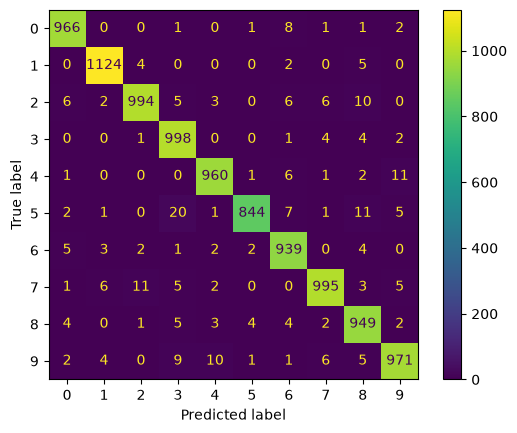

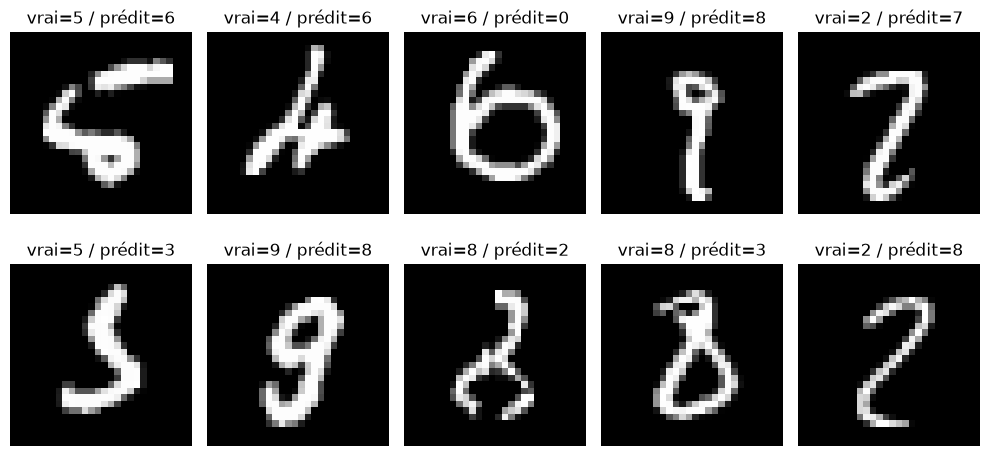

In [14]:
ConfusionMatrixDisplay(confusion_matrix(vrais, preds)).plot()
plt.show()
afficher_erreurs(imgs, vrais, preds, normalise=False)

## Sauvegarde et rechargement

In [15]:
torch.save(model.state_dict(), "mnist_mlp.pth")
nouveau = creer_mlp()
nouveau.load_state_dict(torch.load("mnist_mlp.pth", weights_only=True))
p2, _, _ = predire_tout(nouveau, test_loader)
print("Prédictions identiques après rechargement :", torch.equal(preds, p2))

Prédictions identiques après rechargement : True


---
# Exercice 3 – Classification Iris
## Préparation des données

In [16]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
X_test = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

**Réponses :** 4 colonnes = longueur/largeur des sépales et des pétales ; `torch.long` car `CrossEntropyLoss` attend des indices de classes entiers ; le scaler est ajusté sur le train seul pour éviter toute fuite d'information du test.

## Entraînement (4 → 16 → 3, pas de Softmax en sortie)

In [17]:
def entrainer_iris(model, epochs=200):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    losses = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = criterion(model(X_train), y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if (epoch + 1) % 20 == 0:
            print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")
    return losses

def evaluer(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test).argmax(dim=1)
        acc = (pred == y_test).float().mean()
    return pred, acc

model = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3))
losses = entrainer_iris(model)
pred, acc = evaluer(model)
print(f"Accuracy sur le test : {acc.item():.1%}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432
Accuracy sur le test : 100.0%


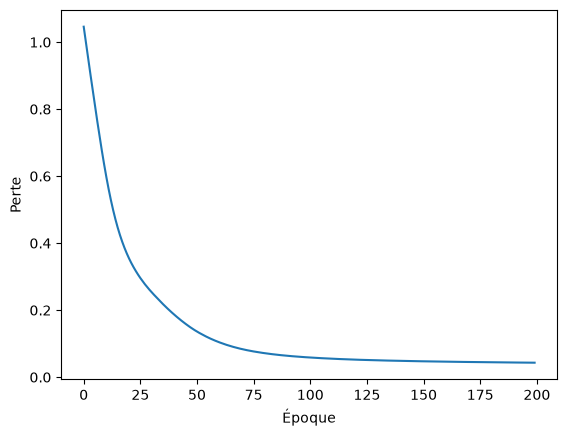

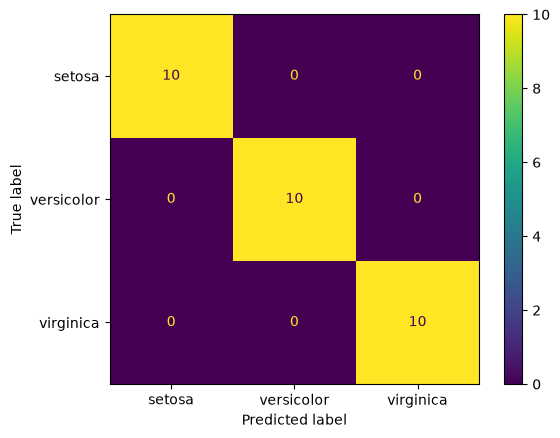

In [18]:
plt.plot(losses); plt.xlabel("Époque"); plt.ylabel("Perte"); plt.show()
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=iris.target_names).plot()
plt.show()

## Comparaison avec un modèle sans couche cachée

In [19]:
torch.manual_seed(42)
lineaire = nn.Linear(4, 3)
entrainer_iris(lineaire)
_, acc_lin = evaluer(lineaire)
print(f"Accuracy modèle linéaire : {acc_lin.item():.1%}")

Époque  20 | Perte : 0.6756
Époque  40 | Perte : 0.5000
Époque  60 | Perte : 0.4248
Époque  80 | Perte : 0.3805
Époque 100 | Perte : 0.3479
Époque 120 | Perte : 0.3209
Époque 140 | Perte : 0.2974
Époque 160 | Perte : 0.2766
Époque 180 | Perte : 0.2581
Époque 200 | Perte : 0.2416
Accuracy modèle linéaire : 90.0%


## Prédiction pour une nouvelle fleur

In [20]:
fleur = torch.tensor(scaler.transform([[5.1, 3.5, 1.4, 0.2]]), dtype=torch.float32)
model.eval()
with torch.no_grad():
    classe = model(fleur).argmax(dim=1).item()
print("Espèce prédite :", iris.target_names[classe])   # setosa

Espèce prédite : setosa


---
# Exercice 4 – MNIST avec un CNN
## Données

In [21]:
torch.manual_seed(42)
train, test, train_loader, test_loader = charger_mnist(normaliser=True)
images, labels = next(iter(train_loader))
print("Images :", images.shape, "| Labels :", labels.shape)   # [64, 1, 28, 28] / [64]

Images : torch.Size([64, 1, 28, 28]) | Labels : torch.Size([64])


**Réponses :** 4 dimensions = (taille du lot, canaux, hauteur, largeur) ; `shuffle=True` évite d'apprendre dans un ordre fixe et décorrèle les lots.

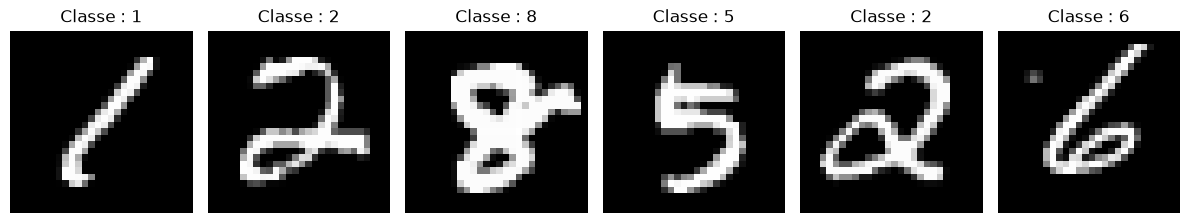

In [22]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow((images[i, 0] * 0.3081 + 0.1307).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Architecture
Tailles : 28×28 → (pool) 14×14 → (pool) 7×7 ; la couche linéaire reçoit 32×7×7 = **1568** valeurs.

In [23]:
class MNISTClassifier(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),          # 28x28 -> 14x14
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),          # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = MNISTClassifier(dropout=0.3).to(device)
with torch.no_grad():
    out = model(images.to(device))
assert out.shape == (images.size(0), 10)
out.shape

torch.Size([64, 10])

## Entraînement et évaluation

In [24]:
entrainer(model, train_loader, len(train), epochs=3)

Époque 1/3 | Perte : 0.1960
Époque 2/3 | Perte : 0.0624
Époque 3/3 | Perte : 0.0464


Accuracy sur le test : 98.85%


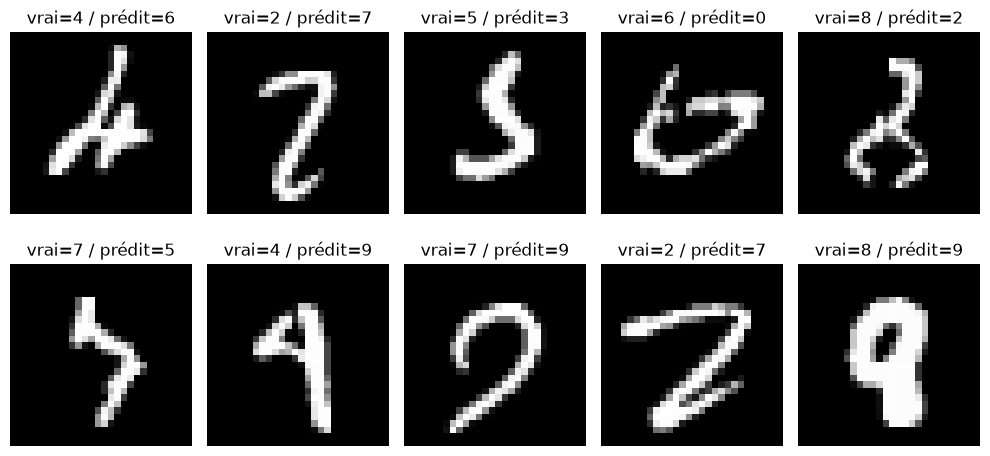

In [25]:
preds, vrais, imgs = predire_tout(model, test_loader)
print(f"Accuracy sur le test : {(preds == vrais).float().mean().item():.2%}")
afficher_erreurs(imgs, vrais, preds, normalise=True)
torch.save(model.state_dict(), "mnist_cnn.pth")